# P7-B: Zero-Shot AI-Generated Text Detection

Ying Yifan  G2602030A

This notebook implements a statistical AI-text detector using GPT-2 perplexity and GLTR token-rank features.

## 1. Environment Setup and Library Imports

In [1]:
import os
import math
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from transformers import GPT2LMHeadModel, GPT2TokenizerFast
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, roc_curve
import joblib

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch:", torch.__version__)


Device: cpu
PyTorch: 2.14.1+cpu


## 2. Loading the Pre-trained GPT-2 Model

We use GPT-2 as a reference language model to estimate token probabilities. 

In [2]:
MODEL_NAME = "gpt2"
MAX_LEN = 512

print("Loading tokenizer...")
tokenizer = GPT2TokenizerFast.from_pretrained(MODEL_NAME)

print("Loading GPT-2...")
model = GPT2LMHeadModel.from_pretrained(MODEL_NAME)
model = model.to(device)
model.eval()

print("GPT-2 loaded successfully!")


Loading tokenizer...


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

F:\Anaconda\envs\p7b\lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\beicheng\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (3 outputs left out)

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 loaded successfully!



## 3. Perplexity Calculation

Perplexity (PPL) measures how well GPT-2 can predict a given text. It is calculated from the probabilities assigned to each token.

$$
\mathrm{PPL} = \exp\left(-\frac{1}{T-1}\sum_{t=2}^{T}\log P(x_t \mid x_{<t})\right)
$$

In this part, I use the GPT-2 tokenizer to convert the text into tokens and then calculate the average negative log-likelihood. The perplexity is obtained by taking the exponential of this value.

A lower PPL means the text is easier for GPT-2 to predict. Since AI-generated text may follow more predictable patterns, PPL can be useful for detection, although it is not always reliable on its own.



In [3]:
def calculate_perplexity(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LEN
    ).to(device)

    input_ids = inputs["input_ids"]

    if input_ids.shape[1] < 2:
        raise ValueError("Text must contain at least two tokens.")

    with torch.no_grad():
        outputs = model(**inputs, labels=input_ids)
        loss = outputs.loss.item()

    return math.exp(loss)


# Test with three sample sentences
sample_texts = [
    "Artificial intelligence is changing the world.",
    "The purple elephant danced on the moon yesterday.",
    "Machine learning models can identify patterns in data."
]

for text in sample_texts:
    ppl = calculate_perplexity(text)
    print(f"Text: {text}")
    print(f"Perplexity: {ppl:.2f}")
    print("-" * 50)


Text: Artificial intelligence is changing the world.
Perplexity: 28.62
--------------------------------------------------
Text: The purple elephant danced on the moon yesterday.
Perplexity: 364.43
--------------------------------------------------
Text: Machine learning models can identify patterns in data.
Perplexity: 62.90
--------------------------------------------------



### Results

The second sentence has the highest perplexity (364.43), while the first sentence has the lowest (28.62). This makes sense because the second sentence contains an unusual combination of words that GPT-2 is less likely to predict.

The results show that perplexity can reflect how predictable a sentence is. However, a low PPL does not necessarily mean the text is AI-generated.



## 4. GLTR Token Rank Analysis

GLTR looks at the rank of each token in GPT-2's predicted vocabulary. If a token has a high predicted probability, its rank will be closer to 1.

I divide the token ranks into four groups: Top 10, 11–100, 101–1000, and above 1000. The proportion of tokens in each group can help show how predictable a text is.

Unlike perplexity, GLTR focuses on the ranking of tokens rather than their exact probabilities.


In [4]:
def calculate_gltr(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LEN
    ).to(device)

    input_ids = inputs["input_ids"]

    if input_ids.shape[1] < 2:
        raise ValueError("Text must contain at least two tokens.")

    with torch.no_grad():
        logits = model(**inputs).logits

    predictions = logits[0, :-1, :]
    targets = input_ids[0, 1:]

    # Rank of each actual token
    target_logits = predictions.gather(
        1, targets.unsqueeze(1)
    )

    ranks = (
        (predictions > target_logits).sum(dim=1) + 1
    ).cpu().numpy()

    # Proportion of tokens in each group
    gltr = [
        np.mean(ranks <= 10),
        np.mean((ranks > 10) & (ranks <= 100)),
        np.mean((ranks > 100) & (ranks <= 1000)),
        np.mean(ranks > 1000)
    ]

    return ranks, gltr

# Test
text = "Artificial intelligence is changing the world."

ranks, gltr = calculate_gltr(text)

print("Token ranks:", ranks)
print("GLTR distribution:")
print("Top 10:", round(gltr[0], 3))
print("Top 11-100:", round(gltr[1], 3))
print("Top 101-1000:", round(gltr[2], 3))
print("Above 1000:", round(gltr[3], 3))

Token ranks: [5752    2    1   39    1    2    1]
GLTR distribution:
Top 10: 0.714
Top 11-100: 0.143
Top 101-1000: 0.0
Above 1000: 0.143



### Results

For the sample sentence, 71.43% of the predicted tokens fall within the Top 10, while 14.29% are ranked above 1000.

Most tokens are highly predictable to GPT-2, but a few have much lower ranks. This shows how GLTR can capture differences in token predictability within the same text.



## 5. GLTR Token Visualization

To make the GLTR results easier to understand, I color each token based on its predicted rank. Green represents the most predictable tokens, followed by yellow, orange, and purple.

This visualization helps show which parts of a sentence are easy or difficult for GPT-2 to predict.



In [5]:
from IPython.display import display, HTML
import html

def visualize_gltr(text):
    ranks, _ = calculate_gltr(text)

    input_ids = tokenizer(
        text,
        truncation=True,
        max_length=MAX_LEN
    )["input_ids"]

    colors = {
        "green": "#90EE90",
        "yellow": "#FFFF99",
        "orange": "#FFCC99",
        "purple": "#D8B4FE"
    }

    colored_text = ""

    # The first token has no preceding context
    first_token = tokenizer.decode([input_ids[0]])
    colored_text += html.escape(first_token)

    for token_id, rank in zip(input_ids[1:], ranks):
        token = tokenizer.decode([token_id])

        if rank <= 10:
            color = colors["green"]
        elif rank <= 100:
            color = colors["yellow"]
        elif rank <= 1000:
            color = colors["orange"]
        else:
            color = colors["purple"]

        colored_text += (
            f'<span style="background-color:{color};'
            f'padding:2px;border-radius:3px;" '
            f'title="Rank: {rank}">'
            f'{html.escape(token)}</span>'
        )

    display(HTML(
        '<div style="font-size:18px;line-height:2.2;">'
        + colored_text + '</div>'
    ))


# Test visualization
visualize_gltr(
    "Artificial intelligence is changing the world."
)


## 6. Dataset Preparation

I use HC3 as the calibration dataset and also keep a separate test set for evaluation. The dataset contains human-written and ChatGPT-generated answers.


In [6]:
import json
import requests
from pathlib import Path

# Create the data directory
DATA_DIR = Path.cwd().parent / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Download the HC3 Open QA subset
url = (
    "https://huggingface.co/datasets/"
    "Hello-SimpleAI/HC3/resolve/main/open_qa.jsonl"
)

file_path = DATA_DIR / "hc3_open_qa.jsonl"

if not file_path.exists():
    print("Downloading HC3 dataset...")
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    file_path.write_bytes(response.content)

# Read the dataset
with open(file_path, "r", encoding="utf-8") as f:
    raw_data = [json.loads(line) for line in f]

print("Total records:", len(raw_data))
print("Available fields:", list(raw_data[0].keys()))


Total records: 1187
Available fields: ['question', 'human_answers', 'chatgpt_answers']


In [7]:
from sklearn.model_selection import train_test_split

records = []

# Keep questions with both human and AI answers
for i, item in enumerate(raw_data):
    human = item.get("human_answers") or []
    ai = item.get("chatgpt_answers") or []

    if not human or not ai:
        continue

    human_text = human[0]
    ai_text = ai[0]

    if (
        isinstance(human_text, str)
        and isinstance(ai_text, str)
        and len(human_text.split()) >= 30
        and len(ai_text.split()) >= 30
    ):
        records.append({
            "pair_id": i,
            "human": human_text,
            "ai": ai_text
        })

pairs = pd.DataFrame(records)

# Remove duplicate answer pairs
pairs = pairs.drop_duplicates(
    subset=["human", "ai"]
).reset_index(drop=True)

if len(pairs) < 80:
    raise ValueError("Not enough valid question pairs.")

# Select separate questions for calibration and testing
calib_pairs, test_pairs = train_test_split(
    pairs,
    train_size=50,
    test_size=30,
    random_state=42
)

def make_dataset(selected_pairs):
    rows = []

    for _, row in selected_pairs.iterrows():
        for label, column in [(0, "human"), (1, "ai")]:
            rows.append({
                "text": row[column],
                "label": label,
                "pair_id": row["pair_id"]
            })

    return pd.DataFrame(rows).sample(
        frac=1, random_state=42
    ).reset_index(drop=True)

calib_df = make_dataset(calib_pairs)
test_df = make_dataset(test_pairs)

# Save the datasets
calib_df.to_csv(DATA_DIR / "hc3_calibration.csv", index=False)
test_df.to_csv(DATA_DIR / "hc3_test.csv", index=False)

print("Valid question pairs:", len(pairs))
print("Calibration set:", len(calib_df))
print("Test set:", len(test_df))

display(calib_df.head())


Valid question pairs: 494
Calibration set: 100
Test set: 60


,text,label,pair_id
0,"The return address is the sender's address, an...",1,141
1,"The expression ""knocking on wood"" is a superst...",1,947
2,Jerky is lean meat that has been trimmed of fa...,0,164
3,World War I was caused by a complex mix of fac...,1,879
4,"The causes of World War I , which began in cen...",0,879


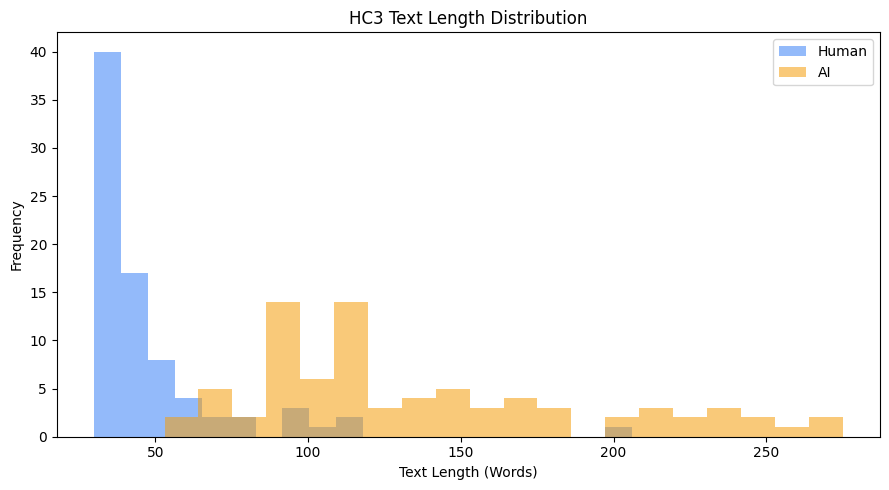

Average Human Length: 48.34
Average AI Length: 137.41


In [10]:
# Combine calibration and test sets for descriptive analysis
hc3_df = pd.concat(
    [calib_df, test_df],
    ignore_index=True
)

# Count words in each text
hc3_df["word_count"] = hc3_df["text"].apply(
    lambda text: len(text.split())
)

human_lengths = hc3_df.loc[
    hc3_df["label"] == 0, "word_count"
]

ai_lengths = hc3_df.loc[
    hc3_df["label"] == 1, "word_count"
]

plt.figure(figsize=(9, 5))

plt.hist(
    human_lengths,
    bins=20,
    alpha=0.55,
    color=HUMAN_COLOR,
    label="Human"
)

plt.hist(
    ai_lengths,
    bins=20,
    alpha=0.55,
    color=AI_COLOR,
    label="AI"
)

plt.xlabel("Text Length (Words)")
plt.ylabel("Frequency")
plt.title("HC3 Text Length Distribution")
plt.legend()
plt.tight_layout()
plt.show()

print("Average Human Length:", round(human_lengths.mean(), 2))
print("Average AI Length:", round(ai_lengths.mean(), 2))



### Dataset Summary

The HC3 subset contains 160 texts, with an equal number of human-written and AI-generated answers.

The average human text length is 48.34 words, while AI-generated texts are much longer, averaging 137.41 words.

This difference may affect the detection results, since perplexity and GLTR statistics can be less stable for shorter texts. I will keep this limitation in mind when evaluating the model.



## 7. Feature Extraction

I use GPT-2 to extract five statistical features from each text: log perplexity and four GLTR token-rank proportions.

Perplexity measures how surprising a text is to GPT-2, while GLTR shows how often the actual tokens appear among the model's most likely predictions.

To reduce CPU computation, I calculate both features in a single forward pass. The extracted features are saved so that I can reuse them for training and evaluation.


In [11]:
import time
import math
import torch
import numpy as np

MAX_LEN = 256

# Use a single GPT-2 forward pass for both PPL and GLTR
def extract_features(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LEN
    ).to(device)

    input_ids = inputs["input_ids"]

    if input_ids.shape[1] < 2:
        raise ValueError("Text must contain at least two tokens.")

    with torch.inference_mode():
        logits = model(**inputs).logits[0]

    # Predict each token using its preceding context
    predictions = logits[:-1]
    targets = input_ids[0, 1:]

    # Compute token-level negative log likelihood
    log_probs = torch.log_softmax(predictions, dim=-1)
    target_log_probs = log_probs.gather(
        1, targets.unsqueeze(1)
    ).squeeze(1)

    log_ppl = -target_log_probs.mean().item()

    # Compute the rank of each observed token
    target_logits = predictions.gather(
        1, targets.unsqueeze(1)
    )

    ranks = (
        (predictions > target_logits).sum(dim=1) + 1
    ).cpu().numpy()

    features = {
        "log_ppl": log_ppl,
        "gltr_top10": float(np.mean(ranks <= 10)),
        "gltr_top100": float(
            np.mean((ranks > 10) & (ranks <= 100))
        ),
        "gltr_top1000": float(
            np.mean((ranks > 100) & (ranks <= 1000))
        ),
        "gltr_above1000": float(np.mean(ranks > 1000))
    }

    return features


In [12]:
sample_text = "Artificial intelligence is changing the world."

sample_features = extract_features(sample_text)

for name, value in sample_features.items():
    print(f"{name}: {value:.4f}")

print("Perplexity:", round(math.exp(sample_features["log_ppl"]), 2))


log_ppl: 3.3542
gltr_top10: 0.7143
gltr_top100: 0.1429
gltr_top1000: 0.0000
gltr_above1000: 0.1429
Perplexity: 28.62


In [13]:
from tqdm.auto import tqdm
import pandas as pd

FEATURE_COLUMNS = [
    "log_ppl",
    "gltr_top10",
    "gltr_top100",
    "gltr_top1000",
    "gltr_above1000"
]

def extract_dataset_features(df, cache_path):
    cache_path = Path(cache_path)

    # Load previously extracted features
    if cache_path.exists():
        results = pd.read_csv(cache_path)
        print(f"Loaded {len(results)} cached samples.")
    else:
        results = pd.DataFrame()

    # Use row indices to resume interrupted runs
    completed = (
        set(results["sample_id"].astype(int))
        if not results.empty else set()
    )

    for i, row in tqdm(
        df.reset_index(drop=True).iterrows(),
        total=len(df),
        desc="Extracting features"
    ):
        if i in completed:
            continue

        try:
            features = extract_features(row["text"])

            result = {
                "sample_id": i,
                "text": row["text"],
                "label": int(row["label"]),
                "pair_id": row["pair_id"],
                "word_count": len(row["text"].split()),
                **features
            }

            results = pd.concat(
                [results, pd.DataFrame([result])],
                ignore_index=True
            )

            # Save progress after every sample
            results.to_csv(cache_path, index=False)

        except Exception as e:
            print(f"Failed on sample {i}: {e}")

    return results.sort_values("sample_id").reset_index(drop=True)


In [14]:
start_time = time.time()

calib_features = extract_dataset_features(
    calib_df,
    DATA_DIR / "hc3_calibration_features.csv"
)

test_features = extract_dataset_features(
    test_df,
    DATA_DIR / "hc3_test_features.csv"
)

elapsed = time.time() - start_time

print(f"Total time: {elapsed / 60:.2f} minutes")
print("Calibration samples:", len(calib_features))
print("Test samples:", len(test_features))

display(calib_features[["label"] + FEATURE_COLUMNS].head())


Extracting features:   0%|          | 0/100 [00:00<?, ?it/s]

Extracting features:   0%|          | 0/60 [00:00<?, ?it/s]

Total time: 0.49 minutes
Calibration samples: 100
Test samples: 60


,label,log_ppl,gltr_top10,gltr_top100,gltr_top1000,gltr_above1000
0,1,2.459873,0.829114,0.101266,0.056962,0.012658
1,1,2.119303,0.835294,0.109804,0.047059,0.007843
2,0,3.894478,0.616667,0.200000,0.133333,0.050000
3,1,2.091593,0.831373,0.109804,0.050980,0.007843
4,0,3.231866,0.725000,0.075000,0.175000,0.025000


In [15]:
# Compare average feature values between the two classes
feature_summary = (
    calib_features
    .groupby("label")[FEATURE_COLUMNS]
    .mean()
    .rename(index={0: "Human", 1: "AI"})
)

display(feature_summary.round(4))

,log_ppl,gltr_top10,gltr_top100,gltr_top1000,gltr_above1000
label,,,,,
Human,3.5286,0.6628,0.1882,0.1016,0.0474
AI,2.2895,0.8290,0.1205,0.0384,0.0122


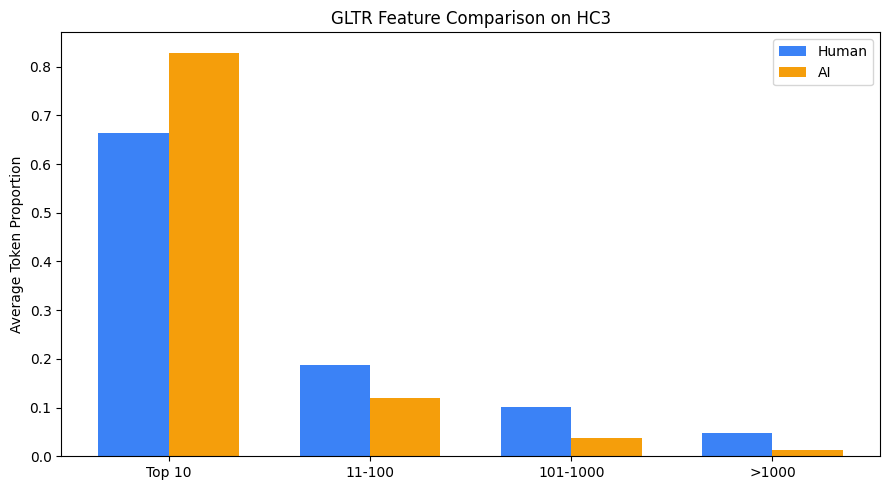

In [16]:
# Compare the average GLTR distributions
gltr_columns = FEATURE_COLUMNS[1:]

human_values = feature_summary.loc["Human", gltr_columns].values
ai_values = feature_summary.loc["AI", gltr_columns].values

x = np.arange(4)
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    human_values,
    width,
    label="Human",
    color=HUMAN_COLOR
)

plt.bar(
    x + width / 2,
    ai_values,
    width,
    label="AI",
    color=AI_COLOR
)

plt.xticks(
    x,
    ["Top 10", "11-100", "101-1000", ">1000"]
)

plt.ylabel("Average Token Proportion")
plt.title("GLTR Feature Comparison on HC3")
plt.legend()
plt.tight_layout()
plt.show()



### Feature Summary

The extracted features show clear differences between human and AI-generated texts.

AI texts have a lower average log perplexity (2.2895) than human texts (3.5286). They also have a higher proportion of Top 10 tokens (82.90% compared with 66.28%).

Human texts contain more low-ranked tokens, especially those ranked above 1000. These results suggest that GPT-2 finds the AI-generated texts more predictable.

However, these differences are only descriptive. I still need to evaluate the classifier on the separate test set to see how well the features generalize.



## 8. Logistic Regression Calibration

GPT-2 is used only for feature extraction, so its parameters are not updated. I train a logistic regression classifier using the five statistical features extracted from the HC3 calibration set.

The classifier learns to estimate the probability that a text is AI-generated. I then evaluate it on the separate HC3 test set using AUROC, F1, and TPR at 1% FPR.

I also visualize the ROC curve, confusion matrix, and predicted probability distributions.


In [18]:
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import joblib

# Prepare calibration and test data
X_calib = calib_features[FEATURE_COLUMNS].values
y_calib = calib_features["label"].astype(int).values

X_test = test_features[FEATURE_COLUMNS].values
y_test = test_features["label"].astype(int).values

# Train logistic regression with standardized features
calibrator = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

calibrator.fit(X_calib, y_calib)

# Save the model in the same folder as the notebook
model_path = Path.cwd() / "P7_B_calib.pkl"
joblib.dump(calibrator, model_path)

print("Current directory:", Path.cwd())
print("Model saved to:", model_path.resolve())
print("Calibration accuracy:", round(calibrator.score(X_calib, y_calib), 4))


Current directory: C:\Users\beicheng\Desktop\P7-ai-detector
Model saved to: C:\Users\beicheng\Desktop\P7-ai-detector\P7_B_calib.pkl
Calibration accuracy: 0.92



### 8.1 Model Evaluation

I evaluate the trained classifier on HC3 test samples that were not used during calibration.

I report AUROC, F1, accuracy, precision, and recall. I also calculate the empirical TPR at 1% FPR, although this metric is less reliable with a small test set.


In [20]:
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score
)

# Prepare the independent test set
X_test = test_features[FEATURE_COLUMNS].values
y_test = test_features["label"].astype(int).values

# Predict AI probabilities and class labels
y_prob = calibrator.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

# Calculate evaluation metrics
auroc = roc_auc_score(y_test, y_prob)
f1 = f1_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

# Calculate the empirical TPR at FPR <= 1%
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
tpr_at_1fpr = tpr[fpr <= 0.01].max()

results = pd.DataFrame([{
    "Dataset": "HC3",
    "AUROC": auroc,
    "F1": f1,
    "TPR@1%FPR": tpr_at_1fpr,
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall
}])

display(results.round(4))


,Dataset,AUROC,F1,TPR@1%FPR,Accuracy,Precision,Recall
0,HC3,0.9622,0.9355,0.5,0.9333,0.9062,0.9667



### 8.2 ROC Curve

The classifier achieves an AUROC of 0.9622 on the HC3 test set, showing good separation between human and AI-generated texts.

The ROC curve shows the trade-off between the true positive rate and false positive rate at different decision thresholds.


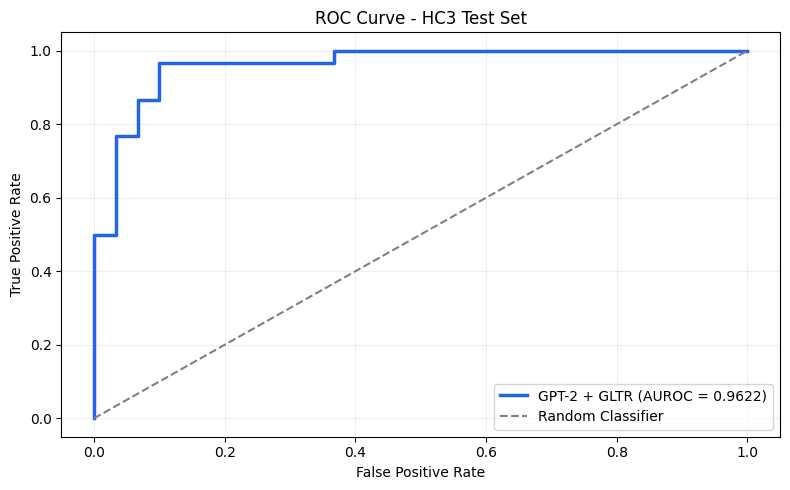

In [21]:
from sklearn.metrics import roc_curve

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    linewidth=2.5,
    color="#2563EB",
    label=f"GPT-2 + GLTR (AUROC = {auroc:.4f})"
)

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - HC3 Test Set")
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.tight_layout()

# Save the figure
plt.savefig(
    DATA_DIR / "hc3_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 8.3 Confusion Matrix

I use a confusion matrix to examine the classification errors on the HC3 test set.

The matrix shows how many human and AI-generated texts are correctly classified, as well as the false positives and false negatives.


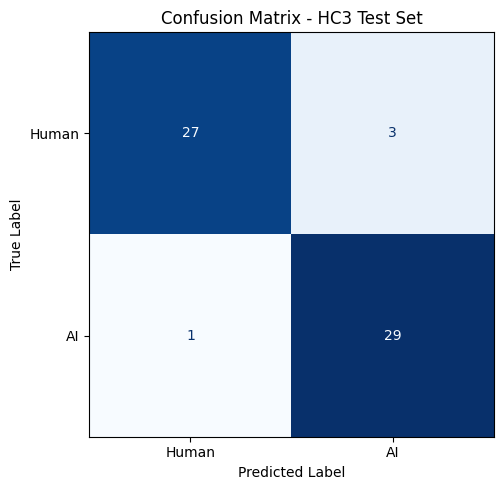

Confusion Matrix:
[[27  3]
 [ 1 29]]


In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Human", "AI"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

plt.title("Confusion Matrix - HC3 Test Set")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()

# Save the figure
plt.savefig(
    DATA_DIR / "hc3_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix:")
print(cm)



### 8.4 AI Probability Distribution

I plot the predicted AI probabilities for human-written and AI-generated texts.

A good detector should assign lower probabilities to human texts and higher probabilities to AI texts. The distribution also helps identify samples where the classifier is uncertain or makes incorrect predictions.


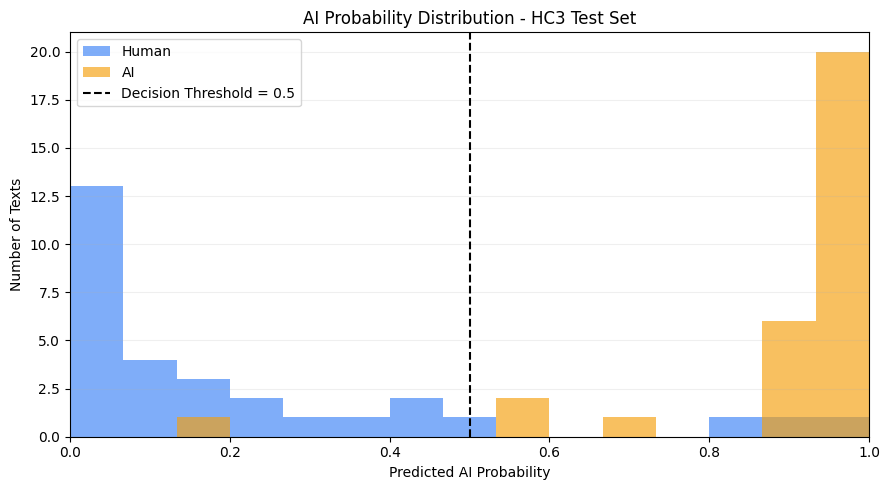

In [23]:

# Separate predicted probabilities by true label
human_probs = y_prob[y_test == 0]
ai_probs = y_prob[y_test == 1]

fig, ax = plt.subplots(figsize=(9, 5))

bins = np.linspace(0, 1, 16)

ax.hist(
    human_probs,
    bins=bins,
    alpha=0.65,
    color=HUMAN_COLOR,
    label="Human"
)

ax.hist(
    ai_probs,
    bins=bins,
    alpha=0.65,
    color=AI_COLOR,
    label="AI"
)

# Show the classification threshold
ax.axvline(
    0.5,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Decision Threshold = 0.5"
)

ax.set_xlabel("Predicted AI Probability")
ax.set_ylabel("Number of Texts")
ax.set_title("AI Probability Distribution - HC3 Test Set")
ax.set_xlim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Save the figure for the final presentation
plt.savefig(
    DATA_DIR / "hc3_probability_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [25]:
# Save test predictions
test_predictions = test_features.copy()

test_predictions["prob_ai"] = y_prob
test_predictions["predicted_label"] = y_pred

test_predictions.to_csv(
    DATA_DIR / "hc3_test_predictions.csv",
    index=False
)

# Save evaluation metrics
hc3_results = pd.DataFrame([{
    "Dataset": "HC3",
    "AUROC": auroc,
    "F1": f1,
    "TPR@1%FPR": tpr_at_1fpr,
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall
}])

hc3_results.to_csv(
    DATA_DIR / "hc3_metrics.csv",
    index=False
)

display(hc3_results.round(4))

print("Predictions and metrics saved successfully.")


,Dataset,AUROC,F1,TPR@1%FPR,Accuracy,Precision,Recall
0,HC3,0.9622,0.9355,0.5,0.9333,0.9062,0.9667


Predictions and metrics saved successfully.



### 8.5 Evaluation Summary

The classifier achieves an AUROC of 0.9622, an F1 score of 0.9355, and an accuracy of 93.33% on the HC3 test set.

Out of 60 test samples, 56 are correctly classified. The model misclassifies three human texts as AI and one AI-generated text as human.

The probability distribution also shows that most human texts receive low AI probabilities, while most AI-generated texts receive high probabilities.

These results are promising, but the evaluation is based on a small HC3 subset. Further experiments on other datasets are needed to check whether the model generalizes well.

The empirical TPR at FPR <= 1% is 0.50. However, with only 30 human samples, this effectively corresponds to a zero-false-positive operating point rather than a reliable estimate at exactly 1% FPR.



## 9. Ablation Study

I compare three feature settings: PPL only, GLTR only, and PPL + GLTR.

Each setting uses the same HC3 calibration and test sets. This helps me understand whether combining perplexity and GLTR improves detection performance.


In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score

feature_sets = {
    "PPL Only": ["log_ppl"],
    "GLTR Only": [
        "gltr_top10",
        "gltr_top100",
        "gltr_top1000",
        "gltr_above1000"
    ],
    "PPL + GLTR": FEATURE_COLUMNS
}

ablation_results = []

for name, columns in feature_sets.items():
    clf = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    )

    clf.fit(calib_features[columns], calib_features["label"])

    probs = clf.predict_proba(test_features[columns])[:, 1]
    preds = (probs >= 0.5).astype(int)
    labels = test_features["label"].values

    ablation_results.append({
        "Method": name,
        "AUROC": roc_auc_score(labels, probs),
        "F1": f1_score(labels, preds),
        "Accuracy": accuracy_score(labels, preds)
    })

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(4))

# Save results
ablation_df.to_csv(DATA_DIR / "hc3_ablation.csv", index=False)


,Method,AUROC,F1,Accuracy
0,PPL Only,0.9667,0.8889,0.8833
1,GLTR Only,0.9556,0.9355,0.9333
2,PPL + GLTR,0.9622,0.9355,0.9333


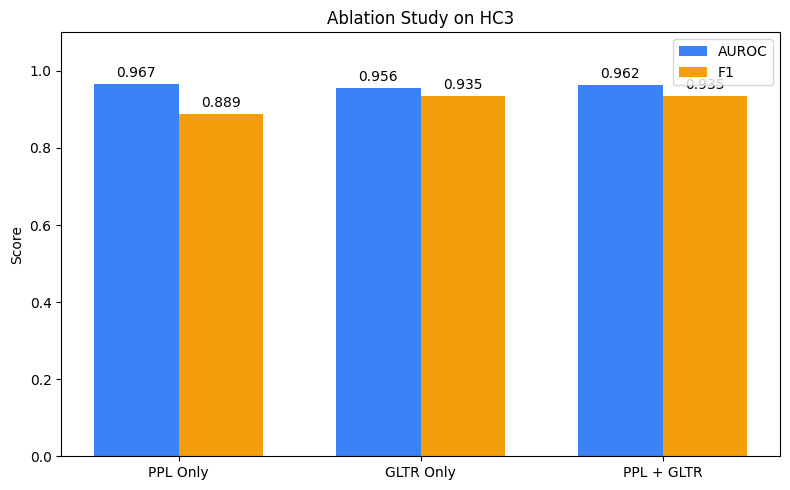

In [27]:
x = np.arange(len(ablation_df))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    x - width / 2,
    ablation_df["AUROC"],
    width,
    label="AUROC",
    color=HUMAN_COLOR
)

ax.bar(
    x + width / 2,
    ablation_df["F1"],
    width,
    label="F1",
    color=AI_COLOR
)

ax.set_xticks(x)
ax.set_xticklabels(ablation_df["Method"])
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score")
ax.set_title("Ablation Study on HC3")
ax.legend()

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.savefig(DATA_DIR / "hc3_ablation.png", dpi=300, bbox_inches="tight")
plt.show()



### Ablation Results

PPL Only achieves the highest AUROC (0.9667), while GLTR Only and PPL + GLTR both achieve an F1 score of 0.9355.

Combining PPL and GLTR does not clearly improve performance on this HC3 subset. This may be because the two feature types capture overlapping information.

I keep the combined model for the remaining experiments and evaluate whether it generalizes better to other datasets.



## 10. Cross-Dataset Evaluation: MAGE

This section evaluates the HC3-trained detector on the MAGE dataset without retraining.

A total of 500 samples are selected, including 250 human-written and 250 AI-generated texts. Stratified random sampling is used to cover multiple text sources and generation models.

The evaluation reports AUROC, F1, accuracy, precision, recall, and TPR at 1% FPR.


In [46]:
from datasets import load_dataset
from collections import defaultdict
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_curve
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

SEED = 42
N_PER_CLASS = 250

rng = random.Random(SEED)

mage_stream = load_dataset(
    "yaful/MAGE",
    split="test",
    streaming=True
)

# Collect eligible samples by class and source
groups = defaultdict(list)

for row in mage_stream:
    text = row["text"]

    if not isinstance(text, str) or len(text.split()) < 30:
        continue

    label = 1 - int(row["label"])
    groups[(label, row["src"])].append(text)

# Stratified sampling across sources
selected = []

for label in [0, 1]:
    sources = [src for (y, src) in groups if y == label]
    rng.shuffle(sources)

    base, remainder = divmod(N_PER_CLASS, len(sources))
    chosen = []

    for i, src in enumerate(sources):
        quota = base + (i < remainder)

        texts = rng.sample(
            groups[(label, src)],
            min(quota, len(groups[(label, src)]))
        )

        chosen.extend(
            {"text": text, "label": label, "source": src}
            for text in texts
        )

    # Fill remaining slots if some sources have too few samples
    if len(chosen) < N_PER_CLASS:
        used = {item["text"] for item in chosen}

        remaining = [
            {"text": text, "label": label, "source": src}
            for src in sources
            for text in groups[(label, src)]
            if text not in used
        ]

        chosen.extend(
            rng.sample(remaining, N_PER_CLASS - len(chosen))
        )

    selected.extend(chosen)

mage_df = pd.DataFrame(selected)

# Shuffle samples
mage_df = mage_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

# Required by the existing feature extraction function
mage_df["pair_id"] = np.arange(len(mage_df))

assert mage_df["label"].value_counts().to_dict() == {
    0: 250,
    1: 250
}

mage_df.to_csv(
    DATA_DIR / "mage_test.csv",
    index=False
)

print("Total samples:", len(mage_df))

print("\nClass distribution:")
print(mage_df["label"].value_counts())

print("\nSource diversity:")
print(mage_df.groupby("label")["source"].nunique())

print("\nAverage word count:")
print(
    mage_df.groupby("label")["text"].apply(
        lambda x: round(x.str.split().str.len().mean(), 1)
    )
)


Total samples: 500

Class distribution:
label
1    250
0    250
Name: count, dtype: int64

Source diversity:
label
0     14
1    250
Name: source, dtype: int64

Average word count:
label
0    213.4
1    213.7
Name: text, dtype: float64


In [47]:
cache_path = DATA_DIR / "mage_features.csv"

# Remove old cached features
if cache_path.exists():
    cache_path.unlink()

# Extract GPT-2 perplexity and GLTR features
mage_features = extract_dataset_features(
    mage_df,
    cache_path
)

assert len(mage_features) == 500
assert mage_features["label"].value_counts().to_dict() == {
    0: 250,
    1: 250
}

print("Extracted samples:", len(mage_features))

print("\nMean feature values:")
display(
    mage_features.groupby("label")[FEATURE_COLUMNS]
    .mean()
    .round(4)
)


Extracting features:   0%|          | 0/500 [00:00<?, ?it/s]

Extracted samples: 500

Mean feature values:


,log_ppl,gltr_top10,gltr_top100,gltr_top1000,gltr_above1000
label,,,,,
0,3.4543,0.6793,0.1890,0.0954,0.0363
1,3.2466,0.7125,0.1865,0.0741,0.0268


In [48]:
X_mage = mage_features[FEATURE_COLUMNS].values
y_mage = mage_features["label"].astype(int).values

# Use the HC3-trained classifier without retraining
mage_prob = calibrator.predict_proba(X_mage)[:, 1]
mage_pred = (mage_prob >= 0.5).astype(int)

mage_fpr, mage_tpr, _ = roc_curve(
    y_mage,
    mage_prob
)

# Maximum observed TPR at FPR <= 1%
tpr_at_1fpr = mage_tpr[mage_fpr <= 0.01].max()

mage_results = pd.DataFrame([{
    "Dataset": "MAGE",
    "Samples": len(y_mage),
    "AUROC": roc_auc_score(y_mage, mage_prob),
    "F1": f1_score(y_mage, mage_pred, zero_division=0),
    "Accuracy": accuracy_score(y_mage, mage_pred),
    "Precision": precision_score(y_mage, mage_pred, zero_division=0),
    "Recall": recall_score(y_mage, mage_pred, zero_division=0),
    "TPR@1%FPR": tpr_at_1fpr
}])

display(mage_results.round(4))

mage_results.to_csv(
    DATA_DIR / "mage_metrics.csv",
    index=False
)

print("\nConfusion matrix:")
print(confusion_matrix(y_mage, mage_pred))

,Dataset,Samples,AUROC,F1,Accuracy,Precision,Recall,TPR@1%FPR
0,MAGE,500,0.6444,0.4611,0.612,0.7545,0.332,0.036



Confusion matrix:
[[223  27]
 [167  83]]


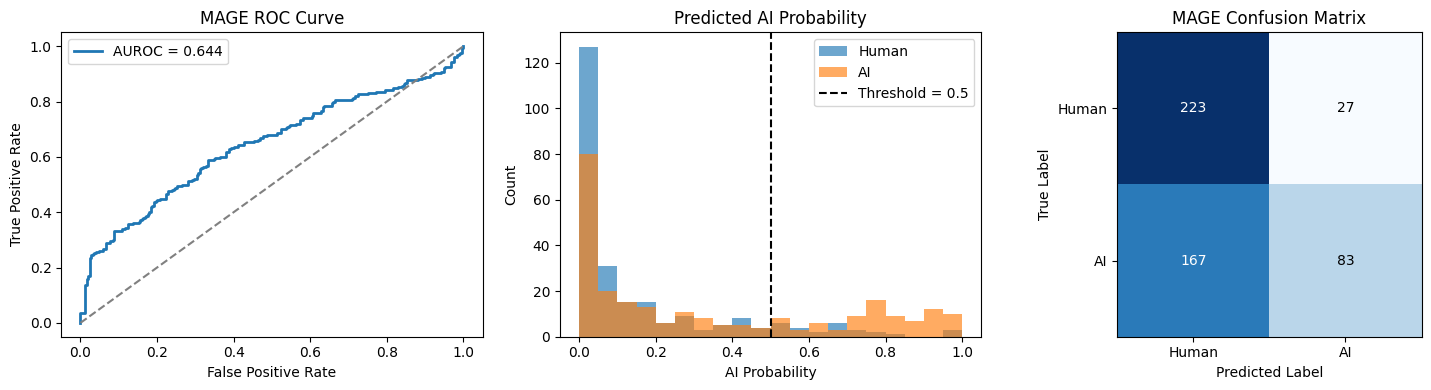

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# ROC curve
axes[0].plot(
    mage_fpr,
    mage_tpr,
    linewidth=2,
    label=f"AUROC = {mage_results['AUROC'].iloc[0]:.3f}"
)
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("MAGE ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

# Predicted AI probability distribution
axes[1].hist(
    mage_prob[y_mage == 0],
    bins=np.linspace(0, 1, 21),
    alpha=0.65,
    label="Human"
)
axes[1].hist(
    mage_prob[y_mage == 1],
    bins=np.linspace(0, 1, 21),
    alpha=0.65,
    label="AI"
)
axes[1].axvline(
    0.5,
    color="black",
    linestyle="--",
    label="Threshold = 0.5"
)
axes[1].set_title("Predicted AI Probability")
axes[1].set_xlabel("AI Probability")
axes[1].set_ylabel("Count")
axes[1].legend()

# Confusion matrix
cm = confusion_matrix(y_mage, mage_pred)

axes[2].imshow(cm, cmap="Blues")

for i in range(2):
    for j in range(2):
        axes[2].text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black"
        )

axes[2].set_xticks([0, 1], ["Human", "AI"])
axes[2].set_yticks([0, 1], ["Human", "AI"])
axes[2].set_xlabel("Predicted Label")
axes[2].set_ylabel("True Label")
axes[2].set_title("MAGE Confusion Matrix")

plt.tight_layout()

plt.savefig(
    DATA_DIR / "mage_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:

comparison = pd.DataFrame([
    {
        "Dataset": "HC3",
        "AUROC": 0.9622,
        "F1": 0.9355,
        "Accuracy": 0.9333
    },
    {
        "Dataset": "MAGE",
        "AUROC": mage_results["AUROC"].iloc[0],
        "F1": mage_results["F1"].iloc[0],
        "Accuracy": mage_results["Accuracy"].iloc[0]
    }
])

display(comparison.round(2))

comparison.to_csv(
    DATA_DIR / "hc3_mage_comparison.csv",
    index=False,
    float_format="%.2f"
)


,Dataset,AUROC,F1,Accuracy
0,HC3,0.96,0.94,0.93
1,MAGE,0.64,0.46,0.61



## 11. Cross-Dataset Evaluation: RAID

This section evaluates the HC3-trained detector on the RAID dataset to assess cross-dataset generalization.

A total of 500 samples are selected, including 250 human-written and 250 AI-generated texts. Samples are drawn from multiple domains and AI generators using stratified reservoir sampling.

Only original texts without adversarial modifications are included. The existing GPT-2 feature extractor and logistic regression classifier are used without retraining.

Performance is measured using AUROC, F1, and TPR@1%FPR.


In [55]:
from datasets import load_dataset
import pandas as pd
import numpy as np

raid_stream = load_dataset(
    "liamdugan/raid", "raid",
    split="train", streaming=True
)

# Shuffle the stream to reduce ordering bias
raid_stream = raid_stream.shuffle(seed=42, buffer_size=10000)

samples = {0: [], 1: []}

for row in raid_stream:
    if row["attack"] != "none":
        continue

    text = row["generation"]
    if not isinstance(text, str) or len(text.split()) < 30:
        continue

    label = 0 if row["model"] == "human" else 1

    if len(samples[label]) < 250:
        samples[label].append({
            "text": text,
            "label": label,
            "source": row["model"],
            "domain": row["domain"]
        })

    if len(samples[0]) == 250 and len(samples[1]) == 250:
        break

raid_df = pd.DataFrame(samples[0] + samples[1])
raid_df = raid_df.sample(frac=1, random_state=42).reset_index(drop=True)
raid_df["pair_id"] = np.arange(len(raid_df))

assert len(raid_df) == 500

raid_df.to_csv(DATA_DIR / "raid_test.csv", index=False)

print(raid_df["label"].value_counts())
print(pd.crosstab(raid_df["domain"], raid_df["label"]))
print(raid_df[raid_df["label"] == 1]["source"].value_counts())


label
1    250
0    250
Name: count, dtype: int64
label        0    1
domain             
abstracts  250  250
source
llama-chat      65
mpt             49
mpt-chat        45
gpt2            33
mistral         30
mistral-chat    28
Name: count, dtype: int64


In [56]:
from sklearn.metrics import (
    roc_auc_score, f1_score, accuracy_score,
    roc_curve, confusion_matrix
)

cache_path = DATA_DIR / "raid_features.csv"

if cache_path.exists():
    cache_path.unlink()

raid_features = extract_dataset_features(raid_df, cache_path)

assert len(raid_features) == 500

X_raid = raid_features[FEATURE_COLUMNS].values
y_raid = raid_features["label"].astype(int).values

raid_prob = calibrator.predict_proba(X_raid)[:, 1]
raid_pred = (raid_prob >= 0.5).astype(int)

fpr, tpr, _ = roc_curve(y_raid, raid_prob)

raid_results = pd.DataFrame([{
    "Dataset": "RAID",
    "AUROC": roc_auc_score(y_raid, raid_prob),
    "F1": f1_score(y_raid, raid_pred),
    "TPR@1%FPR": tpr[fpr <= 0.01].max(),
    "Accuracy": accuracy_score(y_raid, raid_pred)
}])

display(raid_results.round(2))
print("Confusion matrix:")
print(confusion_matrix(y_raid, raid_pred))

raid_results.to_csv(
    DATA_DIR / "raid_metrics.csv",
    index=False,
    float_format="%.2f"
)


Extracting features:   0%|          | 0/500 [00:00<?, ?it/s]

,Dataset,AUROC,F1,TPR@1%FPR,Accuracy
0,RAID,0.75,0.62,0.49,0.72


Confusion matrix:
[[249   1]
 [138 112]]


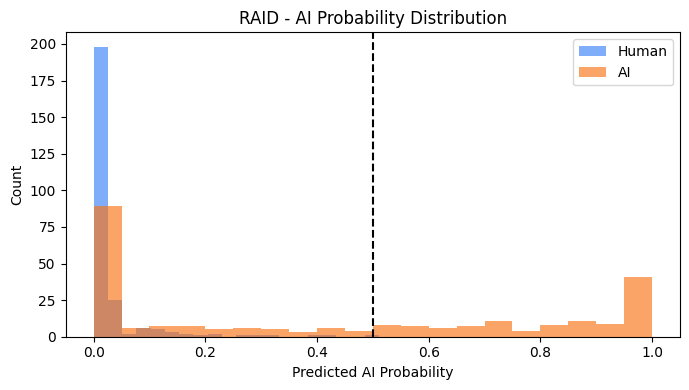

In [57]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.hist(
    raid_prob[y_raid == 0],
    bins=20, alpha=0.65,
    color="#3B82F6", label="Human"
)
plt.hist(
    raid_prob[y_raid == 1],
    bins=20, alpha=0.65,
    color="#F97316", label="AI"
)

plt.axvline(0.5, color="black", linestyle="--")
plt.xlabel("Predicted AI Probability")
plt.ylabel("Count")
plt.title("RAID - AI Probability Distribution")
plt.legend()
plt.tight_layout()

plt.savefig(DATA_DIR / "raid_evaluation.png", dpi=300)
plt.show()



### Cross-Dataset Performance Comparison

The detector achieves its best performance on HC3 (AUROC = 0.96, F1 = 0.94).

Performance decreases on MAGE (AUROC = 0.64, F1 = 0.46) and RAID (AUROC = 0.75, F1 = 0.62), indicating limited cross-dataset generalization.

These results suggest that GPT-2 perplexity and GLTR features are sensitive to differences in text domains and AI generation models.


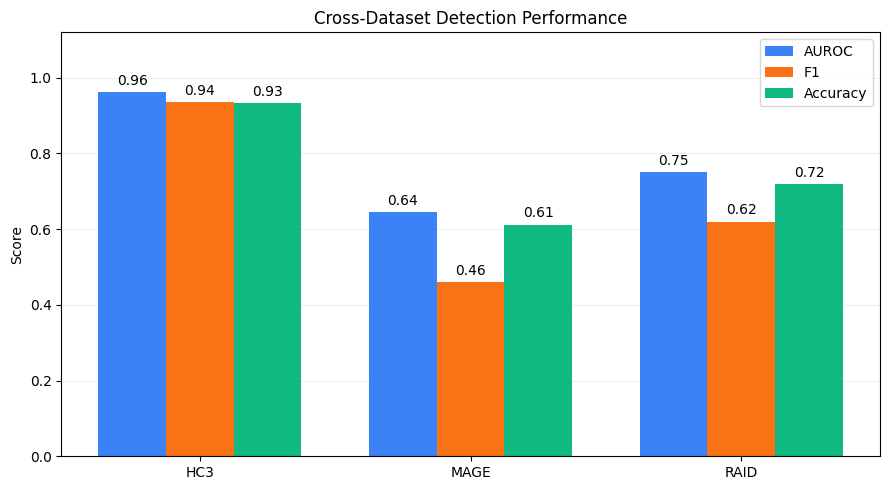

In [58]:

import numpy as np
import matplotlib.pyplot as plt

datasets = ["HC3", "MAGE", "RAID"]

auroc = [0.9622, 0.6444, 0.75]
f1 = [0.9355, 0.4611, 0.62]
accuracy = [0.9333, 0.6120, 0.72]

x = np.arange(len(datasets))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width, auroc, width, label="AUROC", color="#3B82F6")
bars2 = ax.bar(x, f1, width, label="F1", color="#F97316")
bars3 = ax.bar(x + width, accuracy, width, label="Accuracy", color="#10B981")

for bars in [bars1, bars2, bars3]:
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(datasets)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score")
ax.set_title("Cross-Dataset Detection Performance")
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    DATA_DIR / "cross_dataset_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



## 12. Model Integration

We have completed the evaluation of our GPT-2 PPL + GLTR detector on HC3, MAGE, and RAID.

The unseen generator and adversarial attack experiments are handled by other group members. For these experiments, we provide our trained detector through `P7_B_predict.py`.

The GPT-2 model is loaded from Hugging Face, while our trained Logistic Regression classifier is downloaded from [captainfan/p7-gpt2-gltr-detector](https://huggingface.co/captainfan/p7-gpt2-gltr-detector).

The detector can be used with a simple function:

`predict(text: str) -> dict`

Example:

```python
from P7_B_predict import predict

text = "Artificial intelligence is changing education."
result = predict(text)

print(result)
```

Output from our local test:

```python
{
    "prob_ai": 0.0,
    "label": "Human",
    "extra": {
        "truncated": False,
        "ppl": 171.3401,
        "log_ppl": 5.1437,
        "gltr_top10": 0.5,
        "gltr_top100": 0.1667,
        "gltr_top1000": 0.1667,
        "gltr_above1000": 0.1667
    }
}
```

The interface has been tested locally and works. Other group members can use it directly without running our notebook or retraining the classifier.

